<img src="../../images/new_logo_geosdi_colore500-4.png" alt='Logo Selmilab' align='right'  width="144" height="33" />

# MPS19 Seismic Hazard Model 
Data analysis of the [MPS19 seismic hazard model](https://zenodo.org/records/7032251). The archive contains a collection of xlsx files. The ReadMe.pdf file contains a description of the data. In these files, the different sheets list the mean values and the values corresponding to 84th, 16th, 97.5th and 2.5th percentiles for the spectral acceleration, contained in the filename. Values are computed for 10 probabilities of exceedance in 50 years (as reported in the column name) and for rocky soil (class A of the Eurocode 8). Values represent the geometric mean of the horizontal components of the shaking. Values are computed on a regular grid 0.05 degrees spaced, covering the Italian territory.

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import contextily as cx
import cartopy
import cartopy.crs as ccrs

## Peak Ground Accelleration

In [2]:
pga_file_path = 'data/map_PGA.xlsx'

In [3]:
pga_df = pd.read_excel(pga_file_path, sheet_name='mean')
pga_df.head(3)

,lon,lat,81.0,63.0,50.0,39.0,30.0,22.0,10.0,5.0,2.0,1.0
0,6.65,45.10,0.0112,0.0173,0.0228,0.0293,0.0367,0.0466,0.0779,0.1141,0.1780,0.2413
1,6.70,45.05,0.0117,0.0180,0.0238,0.0305,0.0382,0.0484,0.0804,0.1176,0.1828,0.2476
2,6.70,45.10,0.0114,0.0176,0.0233,0.0298,0.0374,0.0474,0.0789,0.1154,0.1796,0.2434


In [5]:
pga_81_df = pga_df[['lon', 'lat', '81.0']]
pga_81_df.head(3)

,lon,lat,81.0
0,6.65,45.10,0.0112
1,6.70,45.05,0.0117
2,6.70,45.10,0.0114


In [6]:
pga_81_gdf = gpd.GeoDataFrame(
    pga_81_df, geometry=gpd.points_from_xy(pga_81_df.lon, pga_81_df.lat), crs="EPSG:4326"
) #.to_crs(epsg=3857)

In [7]:
pga_81_gdf.head(3)

,lon,lat,81.0,geometry
0,6.65,45.10,0.0112,POINT (6.65 45.1)
1,6.70,45.05,0.0117,POINT (6.7 45.05)
2,6.70,45.10,0.0114,POINT (6.7 45.1)


In [8]:
confini_regioni_gdf = gpd.read_file('data/confini_regioni_2026/Reg01012026_WGS84.shp').to_crs(epsg=4326)
confini_regioni_gdf.head(3)

,COD_RIP,COD_REG,DEN_REG,Shape_Leng,Shape_Area,geometry
0,1,1,Piemonte,1.333399e+06,2.538673e+10,"POLYGON ((8.43834 46.4641, 8.43841 46.46378, 8..."
1,1,2,Valle d'Aosta/VallÃ©e d'Aoste,3.258360e+05,3.260843e+09,"POLYGON ((7.57144 45.98758, 7.57241 45.98744, ..."
2,1,3,Lombardia,1.511122e+06,2.386309e+10,"MULTIPOLYGON (((8.81427 45.01739, 8.81351 45.0..."


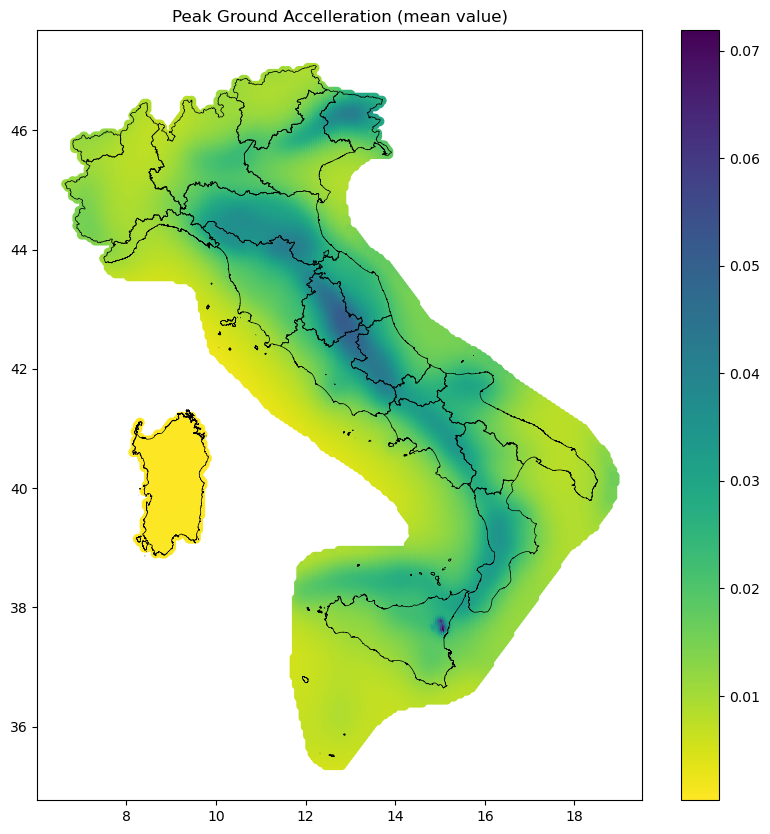

In [9]:
fig, ax = plt.subplots(figsize=(10,10))
pga_81_plot = pga_81_gdf.plot(ax=ax,
                column='81.0',  # Column containing numerical values
                cmap='viridis_r',
                legend=True);  # Continuous colormap
confini_regioni_gdf.plot(ax=ax, color='None', linewidth=0.5, edgecolor='black');
ax.set_title('Peak Ground Accelleration (mean value)');
#cx.add_basemap(ax, crs=pga_81_gdf.crs);

## Spectral Accelleration

In [10]:
sa_file_path = 'data/map_SA_0.05.xlsx'

In [11]:
sa_df = pd.read_excel(sa_file_path, sheet_name='mean')
sa_df.head(3)

,lon,lat,81.0,63.0,50.0,39.0,30.0,22.0,10.0,5.0,2.0,1.0
0,6.65,45.10,0.0161,0.0254,0.0342,0.0444,0.0565,0.0726,0.1241,0.1842,0.2902,0.3950
1,6.70,45.05,0.0169,0.0266,0.0358,0.0465,0.0590,0.0755,0.1284,0.1899,0.2985,0.4055
2,6.70,45.10,0.0165,0.0260,0.0350,0.0454,0.0576,0.0739,0.1259,0.1864,0.2932,0.3986


In [12]:
sa_81_df = sa_df[['lon', 'lat', '81.0']]
sa_81_df.head(3)

,lon,lat,81.0
0,6.65,45.10,0.0161
1,6.70,45.05,0.0169
2,6.70,45.10,0.0165


In [14]:
sa_81_gdf = gpd.GeoDataFrame(
    sa_81_df, geometry=gpd.points_from_xy(sa_81_df.lon, sa_81_df.lat), crs="EPSG:4326"
) #.to_crs(epsg=3857)

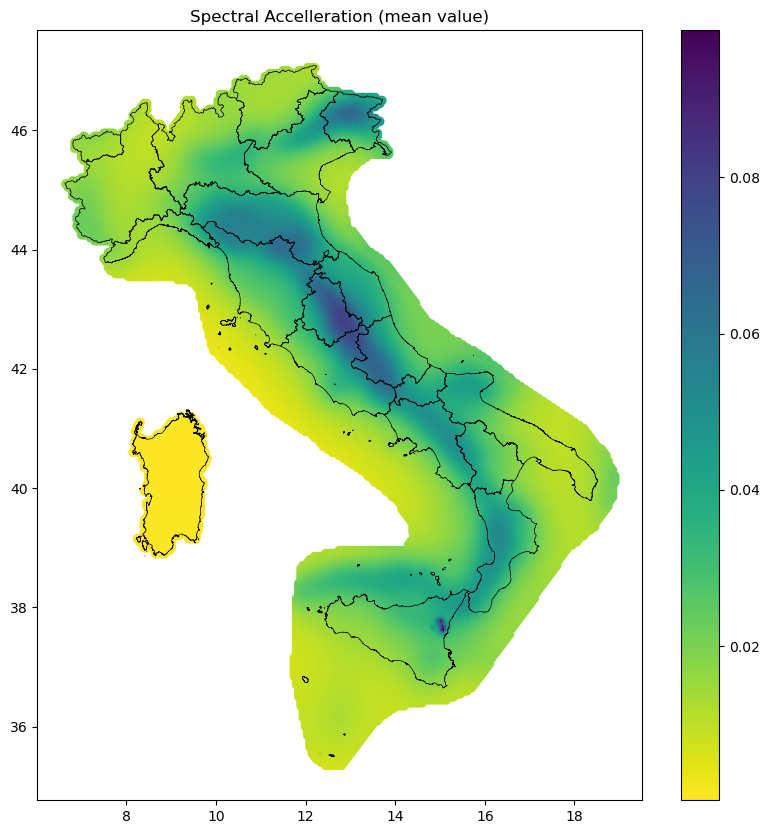

In [15]:
fig, ax = plt.subplots(figsize=(10,10))
sa_81_plot = sa_81_gdf.plot(ax=ax,
                column='81.0',  # Column containing numerical values
                cmap='viridis_r',
                legend=True);  # Continuous colormap
confini_regioni_gdf.plot(ax=ax, color='None', linewidth=0.5, edgecolor='black');
ax.set_title('Spectral Accelleration (mean value)');
#cx.add_basemap(ax, crs=pga_81_gdf.crs);

## References
* [Meletti et al. - MPS19 seismic hazard model of Italy results](https://zenodo.org/records/7032251)
* [INGV - Modello di pericolosità sismica MPS19](https://mps19.pi.ingv.it/)
* [Earthquake Hazard across Europe](http://www.hazard.efehr.org/en/home/)
* [INGV - Zone Sismiche](https://zonesismiche.mi.ingv.it/)
* [OpenQuake](https://www.globalquakemodel.org/product/openquake-engine)
* [Eurocode 8: Design of structures for earthquake resistance](https://eurocodes.jrc.ec.europa.eu/EN-Eurocodes/eurocode-8-design-structures-earthquake-resistance)
* [Baker - Introduction to Probabilistic Seismic Hazard Analysis](https://www.jackwbaker.com/Publications/Baker_(2013)_Intro_to_PSHA_v2.pdf)
* [Cornell - Engineering Seismic Risk Analysis](https://courses.washington.edu/ess502/Cornell_1968.pdf)
* [INGV - CPT15: Catalogo Parametrico dei Terremoti Italiani](https://emidius.mi.ingv.it/CPTI15-DBMI15/)
* [INGV - Open Data Portal](https://data.ingv.it/en/)
* [Wikipedia - Norme tecniche per le costruzioni](https://it.wikipedia.org/wiki/Norme_tecniche_per_le_costruzioni)